In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xgboost as xgb

In [2]:
df=pd.read_csv('Merge_data_v7.csv')

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3129 entries, 0 to 3128
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Unnamed: 0                3129 non-null   int64  
 1   CO2CosIRValue_stat_3      3129 non-null   float64
 2   CO2CosIRValue_stat_9      3129 non-null   float64
 3   CO2CosIRValue_xt_jerk_1   3129 non-null   float64
 4   CO2CosIRValue_tm_dom_2    3129 non-null   float64
 5   CO2CosIRValue_tm_dom_16   3129 non-null   float64
 6   CO2CosIRValue_xf_jerk_9   3129 non-null   float64
 7   CO2CosIRValue_xf_jerk_11  3129 non-null   float64
 8   CO2CosIRValue_xf_jerk_14  3129 non-null   float64
 9   CO2CosIRValue_xf_jerk_15  3129 non-null   float64
 10  COValue_stat_3            3129 non-null   float64
 11  COValue_stat_9            3129 non-null   float64
 12  COValue_xt_jerk_1         3129 non-null   float64
 13  COValue_xt_jerk_5         3129 non-null   float64
 14  COValue_

In [4]:
df.dropna(inplace=True)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3129 entries, 0 to 3128
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Unnamed: 0                3129 non-null   int64  
 1   CO2CosIRValue_stat_3      3129 non-null   float64
 2   CO2CosIRValue_stat_9      3129 non-null   float64
 3   CO2CosIRValue_xt_jerk_1   3129 non-null   float64
 4   CO2CosIRValue_tm_dom_2    3129 non-null   float64
 5   CO2CosIRValue_tm_dom_16   3129 non-null   float64
 6   CO2CosIRValue_xf_jerk_9   3129 non-null   float64
 7   CO2CosIRValue_xf_jerk_11  3129 non-null   float64
 8   CO2CosIRValue_xf_jerk_14  3129 non-null   float64
 9   CO2CosIRValue_xf_jerk_15  3129 non-null   float64
 10  COValue_stat_3            3129 non-null   float64
 11  COValue_stat_9            3129 non-null   float64
 12  COValue_xt_jerk_1         3129 non-null   float64
 13  COValue_xt_jerk_5         3129 non-null   float64
 14  COValue_

In [11]:
df['total_count'].mode()

0    0.0
Name: total_count, dtype: float64

In [12]:
df['move_type'] = df['total_count'].apply(lambda x: 0 if x == 0 else 1 if 1 <= x <= 4 else 2)

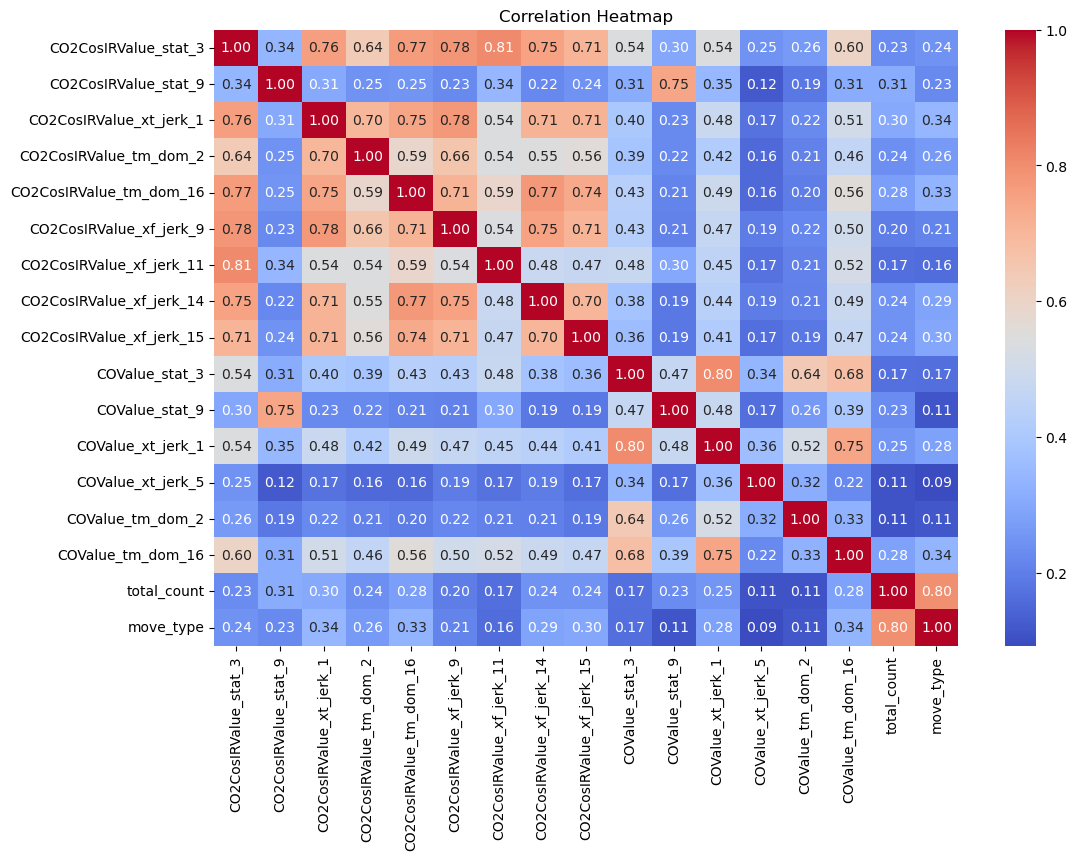

In [15]:
import seaborn as sns
correlation_matrix = df.corr()

# Create a heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

In [14]:
del df['Unnamed: 0']

In [14]:
del df['CO2CosIRValue_stat_9']

In [16]:
del df['CO2CosIRValue_xf_jerk_9']

In [18]:
del df['CO2CosIRValue_tm_dom_13']

In [20]:
del df['CO2CosIRValue_tm_dom_14']

In [22]:
del df['COValue_stat_3']

In [24]:
del df['COValue_stat_9']

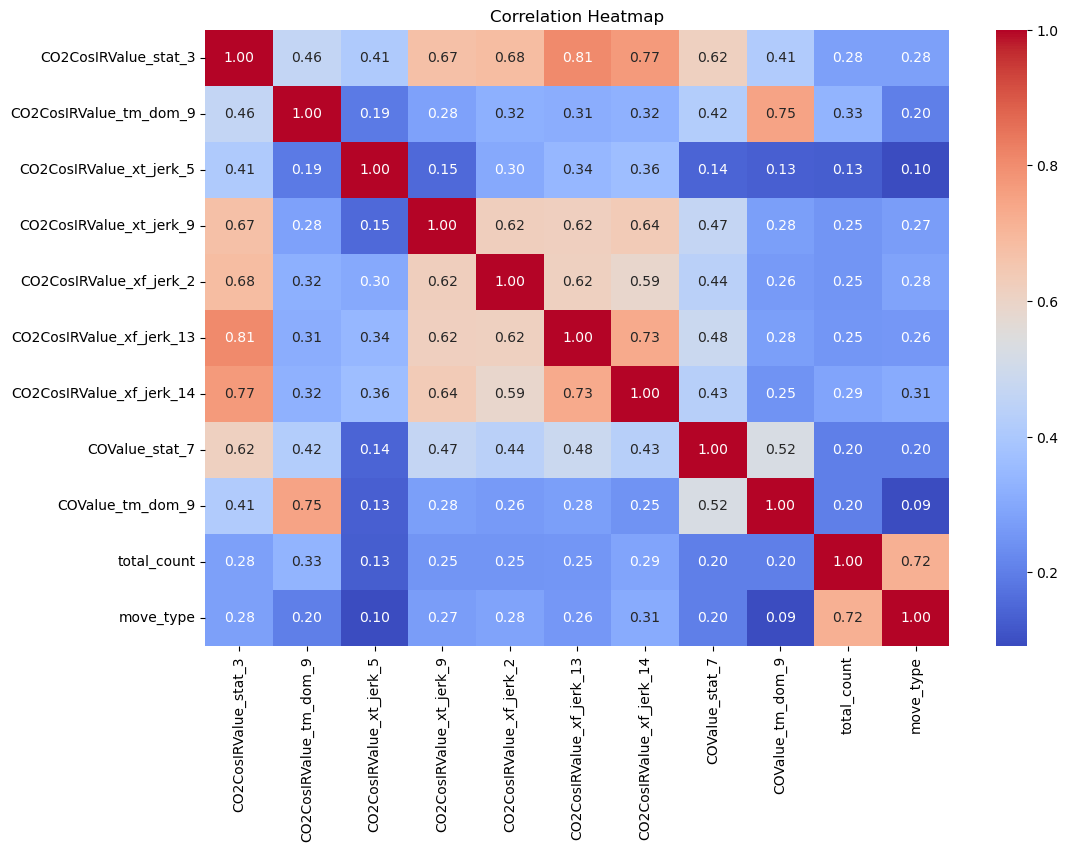

In [25]:
import seaborn as sns
correlation_matrix = df.corr()

# Create a heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

In [16]:
drop_features = ['total_count','move_type']
target_feature = 'move_type'

In [48]:
X = df.drop(drop_features, axis=1)
y = df[target_feature]

In [39]:
from sklearn.preprocessing import StandardScaler

In [43]:
import xgboost as xgb
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
scaler = StandardScaler()
scores=[]
for i in range(1000):
    X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=i)
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)
    xgb_model = xgb.XGBClassifier(objective='multi:softmax',learning_rate=0.1,max_depth=3,n_estimators=30, num_class=len(set(y)))
    xgb_model.fit(X_train,y_train)
    y_pred=xgb_model.predict(X_test)
    scores.append(accuracy_score(y_test, y_pred))

In [44]:
np.argmax(scores)

906

In [45]:
scores[np.argmax(scores)]

0.665389527458493

In [49]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=906)

In [50]:
from sklearn.metrics import classification_report

In [51]:
model=xgb.XGBClassifier(objective='multi:softmax',learning_rate=0.1,max_depth=3,n_estimators=30, num_class=len(set(y)))
model.fit(X_train,y_train)
y_pred=model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")
print("Classification Report:\n", report)

Accuracy: 0.67
Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.86      0.89       242
           1       0.55      0.41      0.47       249
           2       0.57      0.72      0.64       292

    accuracy                           0.67       783
   macro avg       0.68      0.66      0.66       783
weighted avg       0.67      0.67      0.66       783



In [52]:
y_pred_train = model.predict(X_train)
accuracy = accuracy_score(y_train, y_pred_train)
print(f'Accuracy: {accuracy}')

Accuracy: 0.6722080136402387
